# Deep Q Network in JAX+Flax.NNX

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm

In [3]:
from qnrl.buffers import ReplayBuffer

In [4]:
# See save/load example: https://github.com/google/flax/blob/main/examples/nnx_toy_examples/08_save_load_checkpoints.py

class QNet(nnx.Module):
    def __init__(self, din: int, douts: list[int], *, rngs: nnx.Rngs):
        dims = [din, *douts]
        din_dout = list(zip(dims[:-1], dims[1:]))
        self.layers = [
            nnx.Linear(in_features=in_features, out_features=out_features, rngs=rngs)
            for in_features, out_features in din_dout
        ]
        self.din, self.douts = din, douts
    
    @nnx.jit
    def __call__(self, x):
        for layer in self.layers[:-1]: # Apply layer+ReLU to all except last layer.
            x = layer(x)
            x = nnx.relu(x)
        x = self.layers[-1](x) # Apply last layer without any ReLU.
        return x

In [5]:
# Seed the random number generators.
seed = 0
np.random.seed(seed)
key = jax.random.PRNGKey(seed)
key, subkey = jax.random.split(key)

In [6]:
# Initialize the environment.
env_name = 'CartPole-v1'
num_envs = 1
envs = gym.make_vec(env_name, num_envs=num_envs, vectorization_mode="sync", wrappers=[gym.wrappers.RecordEpisodeStatistics])
envs.action_space.seed(seed)

n_actions = int(envs.single_action_space.n)
obs_shape = envs.observation_space.shape

In [7]:
# Create the DQN model
din = int(jnp.prod(jnp.array(obs_shape[1:])))
key, subkey = jax.random.split(key)
model_policy = QNet(din=din, douts=[120, 84, n_actions], rngs=nnx.Rngs(key))
key, subkey = jax.random.split(key)
model_target = QNet(din=din, douts=[120, 84, n_actions], rngs=nnx.Rngs(key))
optimizer = nnx.Optimizer(model_policy, optax.adam(2.5e-4), wrt=nnx.Param)


nnx.display(model_policy)
nnx.display(optimizer)

In [8]:
# observations, _ = envs.reset(seed=seed)
# # observations = jnp.asarray(observations) # Convert to JAX array.
# # observations = jnp.expand_dims(observations, axis=0) # Add batch dimension.
# q_values = model_policy(observations)
# nnx.display(q_values)

In [9]:
envs.action_space.sample()

array([1])

In [10]:
# ###
# # Test the buffer.
# ###
# batch_size = 16
# total_timesteps = 10
# buffer_size = 10
# buffer = ReplayBuffer(buffer_size=buffer_size, env=envs)
# observations, _ = envs.reset(seed=seed) # Reset the environment.
# observations = jnp.asarray(observations) # (num_envs, obs_shape)
# print(f"{observations.shape = }")
# for t in range(total_timesteps):
#     actions = jnp.asarray(envs.action_space.sample())
#     next_observations, rewards, dones, truncations, infos = envs.step(np.array(actions))
#     buffer.add(observations, next_observations, actions, rewards, dones) # Push interaction onto buffer.
#     observations = next_observations

# nnx.display(buffer)

In [11]:
@nnx.jit
def update(
    optimizer: nnx.Optimizer,
    model_policy: QNet,
    model_target: QNet,
    observations: jax.Array,
    actions: jax.Array,
    next_observations: jax.Array,
    rewards: jax.Array,
    dones: jax.Array,
    gamma: float,
    ):
    def mse_loss(model, x, y):
        """Generic MSE loss."""
        y_pred = model(x) # (batch_size, num_actions)
        # print(f"{y_pred.shape = }")
        y_pred = y_pred[jnp.arange(y_pred.shape[0]), actions.squeeze()] # (batch_size,)
        # print(f"{y_pred.shape = }")
        return ((y_pred - y) ** 2.).mean()
    
    q_next_target = model_target(next_observations) # (batch_size, n_actions)
    # print(f"{q_next_target.shape = }")
    q_next_target = jnp.max(q_next_target, axis=-1) # (batch_size,)
    # print(f"{q_next_target.shape = }")
    next_q_value = rewards + (1 - dones) * gamma * q_next_target
    # print(f"{next_q_value.shape = }")
    
    loss, grads = nnx.value_and_grad(mse_loss)(model=model_policy, x=observations, y=next_q_value)
    optimizer.update(model_policy, grads) # Update the policy Q-network in-place.
    
    return loss

def epsilon_schedule_linear(eps_start: float, eps_end: float, duration: int, t: int):
    """Linear epsilon decay schedule."""
    slope = (eps_end - eps_start) / duration
    return max(slope * t, eps_end)

###
# Run the environment.
###
batch_size = 128
total_timesteps = 500_000
learning_starts = 10_000
train_frequency = 10
target_network_frequency = 500
gamma = 0.99
tau = 1.0
report_frequency = 100
buffer_size = 10_000
eps_start = 1
eps_end = 5e-2
eps_exploration = 0.5
buffer = ReplayBuffer(buffer_size=buffer_size, env=envs)
observations, _ = envs.reset(seed=seed) # Reset the environment.
observations = jnp.asarray(observations) # (num_envs, *obs_shape), environment axis is treated as batch index.
print(f"{observations.shape = }")
pbar = tqdm(range(total_timesteps), unit='step', desc="waiting to train", leave=True)
postfix = dict()
history = []
for t in pbar:
    
    # Action selection.
    eps = epsilon_schedule_linear(eps_start=eps_start, eps_end=eps_end, duration=int(eps_exploration*total_timesteps), t=t)
    key, subkey = jax.random.split(key)
    if jax.random.uniform(key=subkey) < eps: # Explore via random action selection.
        actions = jnp.asarray(envs.action_space.sample())
    else:
        q_values = model_policy(observations) # (num_envs, num_actions), environment axis is treated as batch index.
        actions = q_values.argmax(axis=-1) # (num_envs,)
    
    # Interaction within environment using selected actions.
    # print(f"{actions.tolist() = }")
    next_observations, rewards, dones, truncations, infos = envs.step(np.array(actions))
    buffer.add(observations, next_observations, actions, rewards, dones) # Push interaction onto buffer.
    
    
    if "episode" in infos:
        postfix.update(dict(episode_return=infos['episode']['r'], episode_length=infos['episode']['l']))
        history.append(dict(t_episode=t, episode_return=infos['episode']['r'], episode_length=infos['episode']['l']))
    
    if t % report_frequency == 0:
        pbar.set_postfix(postfix)
    
    # Override current observation to be the next observation for subsequent loop iteration.
    observations = next_observations.copy()
    
    if t > learning_starts:
        if t % train_frequency == 0:
            # Update the policy model via a gradient descent step on a minibatch of samples.
            key, subkey = jax.random.split(key)
            minibatch = buffer.sample(key=subkey, batch_size=batch_size)
            loss = update(
                optimizer,
                model_policy,
                model_target,
                minibatch.observations,
                minibatch.actions,
                minibatch.next_observations,
                minibatch.rewards,
                minibatch.dones,
                gamma,
                )
            
            if t % report_frequency == 0:
                pbar.set_description("training", refresh=False)
                postfix.update(dict(loss=loss, t=t))
                pbar.set_postfix(postfix)
                
                history.append(dict(loss=loss, t_loss=t))
        
        if t % target_network_frequency == 0:
            params_policy = nnx.state(model_policy, nnx.Param) # Get the learnable parameters of the policy model.
            params_target = nnx.state(model_target, nnx.Param) # Get the learnable parameters of the target model.
            params_update = optax.incremental_update(params_policy, params_target, tau) # Apply soft update rule for target network weights.
            nnx.update(model_target, params_update)

/Users/derieux/research/qnrl/qnrl/buffers.py:75: UserWarning: Explicitly requested dtype int64 requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  self.actions = jnp.zeros(shape=(self.buffer_size, *self.action_shape), dtype=self.action_space.dtype)


observations.shape = (1, 4)


training: 100%|██████████| 500000/500000 [11:57<00:00, 696.72step/s, episode_return=[211.], episode_length=[211], loss=0.3554224, t=5e+5]    


In [12]:
def listofdict_to_dictoflist(listofdict: list[dict]) -> dict[str,jax.Array]:
    res = {}
    for d in listofdict:
        for k,v in d.items():
            res.setdefault(k, []).append(v)
    res = {k: jnp.array(v) for k,v in res.items()}
    return res

In [13]:
hdict = listofdict_to_dictoflist(history)
hdict

{'t_episode': Array([    10,     20,     30, ..., 499138, 499451, 499663], dtype=int32),
 'episode_return': Array([[ 11.],
        [  9.],
        [  9.],
        ...,
        [288.],
        [312.],
        [211.]], dtype=float32),
 'episode_length': Array([[ 11],
        [  9],
        [  9],
        ...,
        [288],
        [312],
        [211]], dtype=int32),
 'loss': Array([ 2.761673 ,  1.5971408,  1.1375173, ..., 16.53744  , 29.355408 ,
         0.3554224], dtype=float32),
 't_loss': Array([ 10100,  10200,  10300, ..., 499700, 499800, 499900], dtype=int32)}

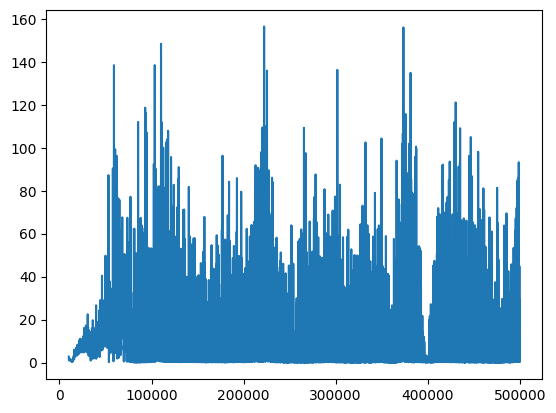

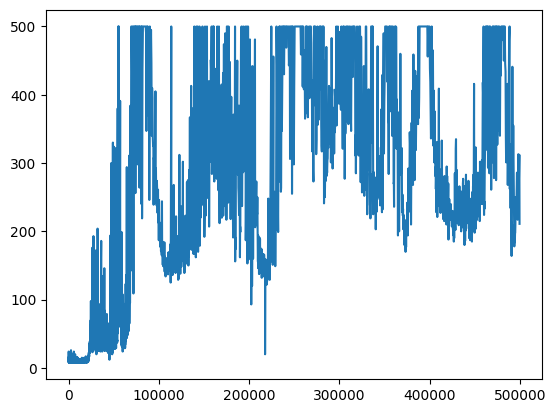

In [16]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(hdict['t_loss'], hdict['loss'])

plt.figure()
plt.plot(hdict['t_episode'], hdict['episode_return'].mean(axis=-1))

In [ ]:
###
# Evaluate the model.
###
observations, _ = envs.reset() # Reset the environment.
for t in range(total_timesteps):
    q_values = model_policy(observations) # (num_envs, num_actions), environment axis is treated as batch index.
    actions = q_values.argmax(axis=-1) # (num_envs,)
    next_observations, rewards, dones, truncations, infos = envs.step(np.array(actions))
    if any(dones):
        break
    
    # Update current observation with next observation.
    observations = next_observations.copy()
    
nnx.display(infos)